# Recorded condition burden and death status in synthetic Delaware EHRs
**Bhakti Doshi | Corrected analysis pipeline**

This notebook replaces the original assessment code with explicit data validation and consistent statistical definitions. **Minimal extracts from the supplied original CSVs are included, and this notebook is executed against them.** The companion `results_review.ipynb` audits historical saved aggregate counts.

This is a retrospective educational analysis of synthetic records. Death status is not a mortality rate per person-time, and these models are not validated predictors of future death. Distinct condition descriptions include historical and potentially non-chronic diagnoses, so they do not measure concurrent chronic multimorbidity.


In [1]:
from pathlib import Path
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
from src.analysis import *
plt.rcParams.update({'figure.figsize': (9, 5), 'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False})


## Data and reference date
The default data directory contains the four compressed analysis extracts. The fixed reference date, **2024-10-04**, is the latest observed encounter START date. It is a transparent data-derived convention, not a verified simulator end date. Override `EHR_DATA_DIR` and `EHR_REFERENCE_DATE` only for a deliberately different analysis. The original used the computer's current date, which made age and group membership change on rerun.

`Age` below means age at the reference date (hypothetical attained age for deceased records), retaining the original birth-cohort interpretation. `Age_at_death` is provided separately and is **not** substituted as a baseline predictor. A future survival study needs a defined entry date, baseline covariates and follow-up.


In [2]:
import os
DATA_DIR = Path(os.environ.get('EHR_DATA_DIR', str(ROOT / 'data' / 'raw')))
REFERENCE_DATE = os.environ.get('EHR_REFERENCE_DATE', '2024-10-04')
tables = load_tables(DATA_DIR)
df = prepare_cohort(tables, REFERENCE_DATE)
print(f'Loaded {len(df):,} synthetic records; cutoff {REFERENCE_DATE}')
FIGURES=ROOT/'figures'; FIGURES.mkdir(exist_ok=True)


Loaded 1,753 synthetic records; cutoff 2024-10-04


## Cohort accounting
Keep the full export as the primary descriptive cohort. The original 8-40 condition restriction is a sensitivity analysis because outcome-informed exclusions can change the result. Age plots show only the named age bands and explicitly report omissions. They do not silently restrict regression samples.


In [3]:
restricted = df.loc[df.Num_Conditions.between(8,40)].copy()
cohort_table = pd.DataFrame([{'cohort':name,'n':len(g),'deaths':int(g.Deceased.sum()),'death_pct':100*g.Deceased.mean()} for name,g in [('Full export',df),('8-40 descriptions',restricted)]])
display(cohort_table)
print('Records outside plotted age bands:', int(df.Age_Group.isna().sum()))
print('Records without classifiable acute/routine encounters:', int(df.Acute_share.isna().sum()))
display(df.groupby('Gender', observed=True).size().rename('n'))


,cohort,n,deaths,death_pct
0,Full export,1753,253,14.432402
1,8-40 descriptions,1716,231,13.461538


Records outside plotted age bands: 0
Records without classifiable acute/routine encounters: 0


Gender
Female    875
Male      878
Name: n, dtype: int64

## Condition burden and uncertainty
The original numeric intervals are retained and labelled correctly: **8-19, 20-29, 30-40**. Every nonempty group's Wilson interval is shown, including groups with zero or all deaths. These intervals describe binomial sampling uncertainty, not uncertainty in the simulator's assumptions.


,Cond_Bin,n,deaths,death_pct,ci_low_pct,ci_high_pct
0,8-19,740,83,11.216216,9.139917,13.693102
1,20-29,749,95,12.683578,10.489179,15.258800
2,30-40,227,53,23.348018,18.316243,29.266830


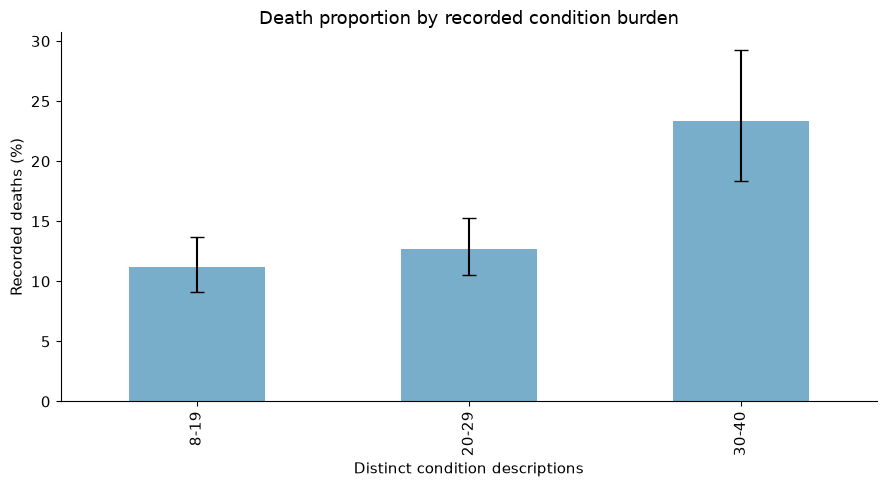

,Age_Group,Cond_Bin,n,deaths,death_pct,ci_low_pct,ci_high_pct
0,20-39,8-19,217,7,3.225806,1.571199,6.507655
1,20-39,20-29,83,2,2.409639,0.663317,8.366309
2,20-39,30-40,6,0,0.000000,0.000000,39.033429
3,40-59,8-19,368,34,9.239130,6.686960,12.633494
4,40-59,20-29,306,19,6.209150,4.010731,9.493420
5,40-59,30-40,66,11,16.666667,9.569583,27.430587
6,60-79,8-19,155,42,27.096774,20.716599,34.584743
7,60-79,20-29,360,74,20.555556,16.702514,25.030349
8,60-79,30-40,155,42,27.096774,20.716599,34.584743


,RACE,Cond_Bin,n,deaths,death_pct,ci_low_pct,ci_high_pct
0,asian,8-19,24,1,4.166667,0.739346,20.241806
1,asian,20-29,30,4,13.333333,5.309655,29.681327
2,asian,30-40,10,3,30.000000,10.779127,60.322185
3,black,8-19,149,23,15.436242,10.511618,22.098290
4,black,20-29,192,32,16.666667,12.060204,22.580806
5,black,30-40,62,17,27.419355,17.881064,39.592540
6,hawaiian,8-19,7,1,14.285714,2.567962,51.312783
7,hawaiian,20-29,8,0,0.000000,0.000000,32.440756
8,hawaiian,30-40,1,0,0.000000,0.000000,79.345069
9,native,8-19,5,0,0.000000,0.000000,43.448246


In [4]:
burden = summarise(restricted, ['Cond_Bin'])
display(burden)
ax = burden.plot.bar(x='Cond_Bin', y='death_pct', legend=False, color='#79aeca',
    yerr=np.vstack([burden.death_pct-burden.ci_low_pct, burden.ci_high_pct-burden.death_pct]), capsize=5)
ax.set(xlabel='Distinct condition descriptions', ylabel='Recorded deaths (%)', title='Death proportion by recorded condition burden')
plt.tight_layout(); plt.savefig(FIGURES/'burden_current.png',dpi=180); plt.show()
display(summarise(restricted, ['Age_Group','Cond_Bin']))
display(summarise(restricted, ['RACE','Cond_Bin']))


## Recorded sex and condition burden
Synthea names its field `GENDER`; this analysis describes its Female/Male categories and does not infer gender identity. The three stratum comparisons form one Holm correction family. Absent groups are not replaced with invented denominators. A continuity correction is explicitly flagged if a 2x2 cell is zero.


In [5]:
sex_summary = summarise(restricted,['Cond_Bin','Gender'])
display(sex_summary)
rows=[]
for label,g in restricted.groupby('Cond_Bin', observed=True):
    f=g[g.Gender.eq('Female')]; m=g[g.Gender.eq('Male')]
    rows.append({'group':label,**compare_sexes(len(f),int(f.Deceased.sum()),len(m),int(m.Deceased.sum()))})
sex_tests=pd.DataFrame(rows)
sex_tests['p_holm']=holm_adjust(sex_tests.p_value)
display(sex_tests)


,Cond_Bin,Gender,n,deaths,death_pct,ci_low_pct,ci_high_pct
0,8-19,Female,374,30,8.021390,5.676319,11.220042
1,8-19,Male,366,53,14.480874,11.244391,18.455216
2,20-29,Female,384,38,9.895833,7.294824,13.291283
3,20-29,Male,365,57,15.616438,12.252615,19.696466
4,30-40,Female,102,17,16.666667,10.674217,25.078748
5,30-40,Male,125,36,28.800000,21.587484,37.276689


,group,ratio,ci_low,ci_high,p_value,test,continuity_correction,p_holm
0,8-19,1.805282,1.181439,2.758537,0.005369,Pearson chi-square,False,0.016108
1,20-29,1.578082,1.074181,2.318364,0.018698,Pearson chi-square,False,0.037396
2,30-40,1.728000,1.033427,2.889399,0.031596,Pearson chi-square,False,0.037396


## Medication and encounter history
Counts are distinct medication descriptions and encounter rows accumulated by the cutoff. They are not concurrent prescriptions, treatment intensity or time-standardised utilisation. Actual medication counts replace the original bin-midpoint approximation.


In [6]:
display(summarise(df,['Med_Bin']))
display(restricted.groupby(['Cond_Bin','Gender'],observed=True).agg(
    n=('Id','size'), mean_medications=('Num_Medications','mean'),mean_encounters=('Num_Encounters','mean')))
heat = summarise(restricted,['Cond_Bin','Med_Bin'])
display(heat[['Cond_Bin','Med_Bin','n','deaths','death_pct','ci_low_pct','ci_high_pct']])


,Med_Bin,n,deaths,death_pct,ci_low_pct,ci_high_pct
0,0,31,3,9.677419,3.346464,24.899938
1,1-2,234,21,8.974359,5.944683,13.329273
2,3-5,513,55,10.721248,8.329995,13.696384
3,6-10,655,111,16.946565,14.268124,20.010450
4,11+,320,63,19.687500,15.701364,24.392779


n  mean_medications  mean_encounters
Cond_Bin Gender                                        
8-19     Female  374          5.580214        55.791444
         Male    366          3.592896        39.043716
20-29    Female  384          8.083333        92.932292
         Male    365          8.126027        86.972603
30-40    Female  102         11.686275       237.245098
         Male    125         11.384000       298.072000

,Cond_Bin,Med_Bin,n,deaths,death_pct,ci_low_pct,ci_high_pct
0,8-19,0,27,2,7.407407,2.055465,23.369593
1,8-19,1-2,181,9,4.972376,2.637736,9.178584
2,8-19,3-5,294,30,10.204082,7.241527,14.193185
3,8-19,6-10,207,34,16.425121,11.998508,22.075179
4,8-19,11+,31,8,25.806452,13.701706,43.246136
5,20-29,0,3,0,0.000000,0.000000,56.149703
6,20-29,1-2,43,2,4.651163,1.284926,15.455498
7,20-29,3-5,193,16,8.290155,5.167141,13.041147
8,20-29,6-10,342,51,14.912281,11.527664,19.076376
9,20-29,11+,168,26,15.476190,10.785550,21.710368


## Encounter composition
Shares use acute plus routine encounters as the denominator. Other encounter classes are counted separately. Patients with no eligible encounters have missing shares rather than artificial zero percentages. Routine share is the complement of acute share, so testing both would duplicate the same comparison. Holm adjustment covers the three acute-share tests.


In [7]:
from scipy.stats import mannwhitneyu
rows=[]
for label,g in restricted.groupby('Cond_Bin',observed=True):
    f=g.loc[g.Gender.eq('Female'),'Acute_share'].dropna()
    m=g.loc[g.Gender.eq('Male'),'Acute_share'].dropna()
    p=mannwhitneyu(f,m,alternative='two-sided').pvalue if len(f) and len(m) else np.nan
    rows.append({'group':label,'female_n':len(f),'male_n':len(m),'female_median':f.median(),'male_median':m.median(),'p_value':p})
care_tests=pd.DataFrame(rows); care_tests['p_holm']=holm_adjust(care_tests.p_value)
display(care_tests)
print('Other-class encounter rows:', int(df.Other.sum()))


,group,female_n,male_n,female_median,male_median,p_value,p_holm
0,8-19,374,366,5.128205,4.761905,0.698993,1.00000
1,20-29,384,365,7.594937,8.000000,0.203690,0.61107
2,30-40,102,125,11.727504,11.641221,0.955443,1.00000


Other-class encounter rows: 1333


## Exploratory diagnosis flags
Description keywords support exploratory grouping only. They can include history, suspected disease, benign neoplasms or ambiguous descriptions. These are **not validated severity measures**. Conditions overlap, so condition-specific percentages need not add to 100. Audit the diagnosis descriptions before interpreting any category.


In [8]:
flags=['Has_'+name for name in MAJOR_RULES]
prevalence=restricted.groupby('Gender',observed=True)[flags].mean().T.mul(100)
display(prevalence)
major=restricted.loc[restricted[flags].any(axis=1)]
display(summarise(major,['Gender']))
for name,pattern in MAJOR_RULES.items():
    matches=tables['conditions'].DESCRIPTION.str.contains(pattern,case=False,na=False,regex=True)
    print(name, sorted(tables['conditions'].loc[matches,'DESCRIPTION'].unique()))


Gender,Female,Male
Has_Diabetes,61.162791,66.471963
Has_CKD,16.744186,23.481308
Has_COPD,4.186047,4.556075
Has_Cancer,6.976744,4.789720
Has_Heart failure,2.790698,3.855140
Has_Stroke,0.232558,0.934579
Has_Hypertension,47.441860,57.359813


,Gender,n,deaths,death_pct,ci_low_pct,ci_high_pct
0,Female,656,70,10.670732,8.532885,13.266512
1,Male,703,126,17.923186,15.264630,20.930398


Diabetes ['Diabetes mellitus type 2 (disorder)', 'Disorder of kidney due to diabetes mellitus (disorder)', 'Macular edema and retinopathy due to type 2 diabetes mellitus (disorder)', 'Microalbuminuria due to type 2 diabetes mellitus (disorder)', 'Neuropathy due to type 2 diabetes mellitus (disorder)', 'Nonproliferative diabetic retinopathy due to type 2 diabetes mellitus (disorder)', 'Prediabetes', 'Proliferative diabetic retinopathy due to type II diabetes mellitus (disorder)', 'Proteinuria due to type 2 diabetes mellitus (disorder)', 'Retinopathy due to type 2 diabetes mellitus (disorder)']
CKD ['Chronic kidney disease stage 1 (disorder)', 'Chronic kidney disease stage 2 (disorder)', 'Chronic kidney disease stage 3 (disorder)', 'Chronic kidney disease stage 4 (disorder)']


COPD ['Chronic obstructive bronchitis (disorder)', 'Pulmonary emphysema (disorder)']


Cancer ['Carcinoma in situ of prostate (disorder)', 'Malignant neoplasm of breast (disorder)', 'Malignant tumor of colon', 'Metastasis from malignant tumor of prostate (disorder)', 'Neoplasm of prostate', 'Non-small cell carcinoma of lung  TNM stage 1 (disorder)', 'Non-small cell lung cancer (disorder)', 'Overlapping malignant neoplasm of colon', 'Primary malignant neoplasm of colon', 'Primary small cell malignant neoplasm of lung  TNM stage 1 (disorder)', 'Secondary malignant neoplasm of colon', 'Small cell carcinoma of lung (disorder)', 'Suspected lung cancer (situation)', 'Suspected prostate cancer (situation)']
Heart failure ['Chronic congestive heart failure (disorder)', 'Heart failure (disorder)']


Stroke ['Stroke']
Hypertension ['Essential hypertension (disorder)']


## Retrospective logistic associations and sensitivity analysis
Fit the same formulas to the full cohort and the original restricted cohort, reporting each model's sample size. The interaction is its own model, not a row in the fully adjusted model. Centering condition counts makes the main sex coefficient refer to mean burden.

Medication and encounter histories may reflect events close to death. No model supports causal, mediation, biological-mechanism or prospective risk claims. A nonsignificant interaction is insufficient evidence for modification on the log-odds scale, not proof of identical effects or equal absolute differences.


In [9]:
formulas={
 'Unadjusted':'Deceased ~ Num_Conditions',
 'Age and sex adjusted':'Deceased ~ C(Gender) + Age + Num_Conditions',
 'Interaction':'Deceased ~ C(Gender)*Conditions_centered + Age',
 'Exploratory utilisation':'Deceased ~ C(Gender) + Age + Num_Conditions + Num_Medications + Num_Encounters',
}
models=[]
for cohort,g in [('Full export',df),('8-40 descriptions',restricted)]:
    g=g.copy(); g['Conditions_centered']=g.Num_Conditions-g.Num_Conditions.mean()
    for name,formula in formulas.items():
        result=model_table(g,formula); result.insert(0,'model',name); result.insert(0,'cohort',cohort)
        models.append(result)
model_results=pd.concat(models,ignore_index=True)
display(model_results)
OUT=ROOT/'outputs'; OUT.mkdir(exist_ok=True)
for name,table in [('cohorts',cohort_table),('burden',burden),('sex_tests',sex_tests),('care_tests',care_tests),('models',model_results)]:
    table.to_csv(OUT/(name+'.csv'),index=False)


,cohort,model,term,OR,ci_low,ci_high,p_value,n
0,Full export,Unadjusted,Intercept,0.110752,0.072852,0.168371,7.322057e-25,1753
1,Full export,Unadjusted,Num_Conditions,1.019262,1.001365,1.037478,3.478167e-02,1753
2,Full export,Age and sex adjusted,Intercept,0.002372,0.000991,0.005676,5.562914e-42,1753
3,Full export,Age and sex adjusted,C(Gender)[T.Male],1.836473,1.378373,2.446823,3.297315e-05,1753
4,Full export,Age and sex adjusted,Age,1.082815,1.067148,1.098712,1.022441e-26,1753
5,Full export,Age and sex adjusted,Num_Conditions,0.967272,0.947392,0.987569,1.686283e-03,1753
6,Full export,Interaction,Intercept,0.001159,0.000457,0.002935,4.152078e-46,1753
7,Full export,Interaction,C(Gender)[T.Male],1.831312,1.372317,2.443827,3.958113e-05,1753
8,Full export,Interaction,Conditions_centered,0.964926,0.933264,0.997662,3.595112e-02,1753
9,Full export,Interaction,C(Gender)[T.Male]:Conditions_centered,1.003777,0.964030,1.045162,8.549054e-01,1753


## Interpretation checklist
Report exact denominators, model formula and cutoff. Compare the full and restricted cohorts before drawing conclusions. Condition counts are an EHR history measure, and death proportions are not incidence rates. Do not rank predictors by odds ratios on different units or describe a significant association as a validated prediction model. The accompanying portfolio essay and presentation use this rerun and distinguish the restricted-cohort results from the full-cohort sensitivity comparison.

Data format: [Synthea CSV dictionary](https://github.com/synthetichealth/synthea/wiki/CSV-File-Data-Dictionary). Source context: [Walonoski et al. (2018)](https://doi.org/10.1093/jamia/ocx079).
